# Lab 1 – podstawowa analiza obrazu

W tym ćwiczeniu samodzielnie przeprowadzisz podstawową analizę obrazu cyfrowego z wykorzystaniem biblioteki `scikit-image`.

Twoim celem jest przejście przez cały prosty proces analizy:

**wczytanie obrazu → sprawdzenie jego właściwości → analiza kanałów → skala szarości → histogram → normalizacja → wyrównanie histogramu**


## 1. Wybierz obraz

Wybierz jeden obraz z wbudowanej bazy:

```python
skimage.data
```

Możesz wykorzystać np.:

```python
data.camera()
data.coins()
data.chelsea()
data.coffee()
data.horse()
data.moon()
data.rocket()
```

Nie wybieraj obrazu `astronaut`, ponieważ był już analizowany podczas zajęć.

Wyświetl wybrany obraz.


In [1]:
def show_row(images, titles=None, cmap=None):
    """
    Wyświetla kilka obrazów obok siebie w jednym wierszu.

    Parametry:
    -----------
    images : list
        Lista obrazów (tablic NumPy) do wyświetlenia.
    titles : list (opcjonalnie)
        Lista tytułów dla każdego obrazu.
    cmap : str (opcjonalnie)
        Mapa kolorów (np. 'gray' dla obrazów w skali szarości).
    """

    n = len(images)                          # Liczba obrazów
    fig, axes = plt.subplots(1, n)           # Tworzy jeden wiersz z n kolumnami (dla każdego obrazu jedna oś)

    # Iteracja po wszystkich obrazach i ich osiach
    for i, ax in enumerate(np.atleast_1d(axes)):
        ax.imshow(images[i], cmap=cmap)      # Wyświetla obraz (z opcjonalną mapą kolorów)
        ax.axis('off')                       # Ukrywa osie (ramki, skale, liczby)
        if titles:                           # Jeśli podano tytuły
            ax.set_title(titles[i])          # Ustawia tytuł nad obrazem

    plt.show()

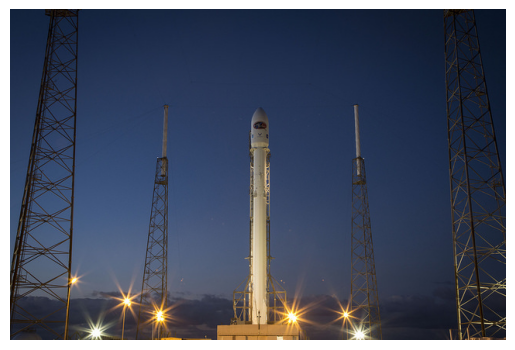

In [ ]:
from skimage import data, color, exposure, img_as_float
import numpy as np
import matplotlib.pyplot as plt

# Wczytaj wybrany obraz
img = data.rocket()

# Wyświetl obraz
plt.imshow(img)
plt.axis("off")
plt.show()



## 2. Sprawdź podstawowe informacje o obrazie

Sprawdź:

```python
img.shape
img.dtype
img.min()
img.max()
```

Zwróć uwagę na:

- wymiary obrazu,
- liczbę kanałów,
- typ danych,
- minimalną i maksymalną wartość pikseli.

### Zastanów się

Co informacje zwracane przez `shape` mówią o obrazie?  
Czy wartości pikseli są zapisane w zakresie `0–255`, czy `0–1`?


In [12]:
print("Wymiary obrazu:", img.shape)
print("Typ danych:", img.dtype)
print("Minimalna wartość:", img.min())
print("Maksymalna wartość:", img.max())


Wymiary obrazu: (427, 640, 3)
Typ danych: uint8
Minimalna wartość: 0
Maksymalna wartość: 255


## Odp

427x640 pixeli i 3 wymiary kolorow (RGB)

## 3. Określ rodzaj obrazu

Na podstawie wymiarów określ, czy obraz jest:

- obrazem w skali szarości,
- obrazem RGB,
- obrazem RGBA.

Przykładowo:

```text
(wysokość, szerokość)
```

oznacza zazwyczaj obraz w skali szarości,

natomiast:

```text
(wysokość, szerokość, 3)
```

oznacza obraz RGB.


### Odp 
wysokosc < szerokosci wiec opcja druga czyli obraz RGB 

## 4. Przeanalizuj kanały obrazu

Jeżeli wybrany obraz jest obrazem RGB, wydziel jego trzy kanały:

- R – czerwony,
- G – zielony,
- B – niebieski.

Wyświetl obok siebie:

**obraz RGB | kanał R | kanał G | kanał B**

Kanały możesz wyświetlić w skali szarości, ponieważ wtedy jasność piksela pokazuje intensywność danego kanału.

### Zastanów się

W których fragmentach obrazu poszczególne kanały są najjaśniejsze?  
Czy da się powiązać to z kolorami widocznymi na obrazie oryginalnym?

Jeśli obraz jest już w skali szarości, pomiń ten etap.


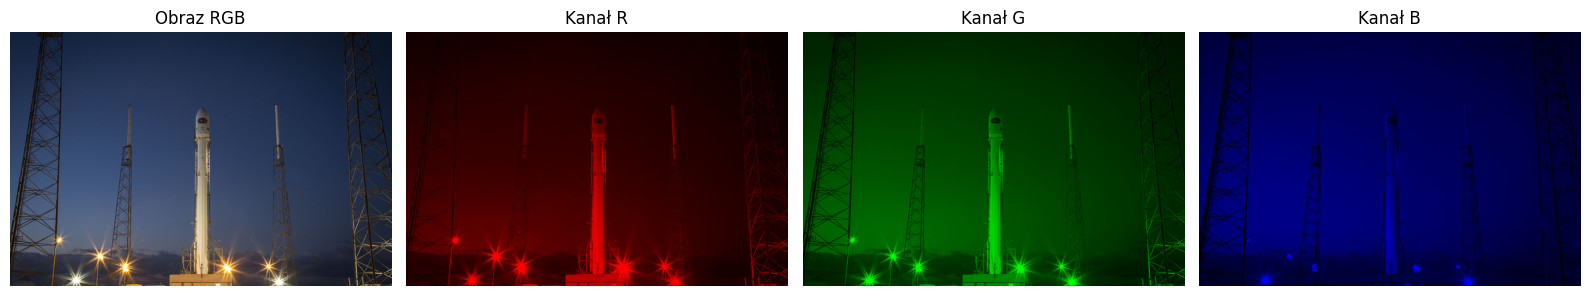

In [16]:
# Jeśli obraz jest RGB, wyświetl jego kanały R, G i B

import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# ============================================================
# Wczytanie obrazu
# ============================================================
img_rgb = data.rocket()

# ============================================================
# Podgląd RGB i kanałów R / G / B
# ============================================================

# Kanał czerwony
red = np.zeros_like(img_rgb)
red[:, :, 0] = img_rgb[:, :, 0]

# Kanał zielony
green = np.zeros_like(img_rgb)
green[:, :, 1] = img_rgb[:, :, 1]

# Kanał niebieski
blue = np.zeros_like(img_rgb)
blue[:, :, 2] = img_rgb[:, :, 2]

# Wyświetlenie obrazu RGB oraz poszczególnych kanałów
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_rgb)
axes[0].set_title("Obraz RGB")
axes[0].axis("off")

axes[1].imshow(red)
axes[1].set_title("Kanał R")
axes[1].axis("off")

axes[2].imshow(green)
axes[2].set_title("Kanał G")
axes[2].axis("off")

axes[3].imshow(blue)
axes[3].set_title("Kanał B")
axes[3].axis("off")

plt.tight_layout()
plt.show()



## 5. Przekonwertuj obraz do skali szarości

Jeżeli obraz jest kolorowy, przekonwertuj go do skali szarości:

```python
gray = color.rgb2gray(img)
```

Wyświetl obraz przed i po konwersji.

Ponownie sprawdź:

```python
gray.shape
gray.dtype
gray.min()
gray.max()
```

### Zastanów się

Co zmieniło się w strukturze danych po usunięciu informacji o kolorze?


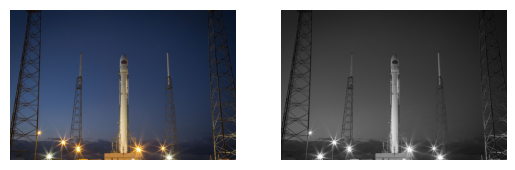

Shape: (427, 640)
Type: float64
Min: 0.0
Max: 1.0


In [26]:
# Utwórz obraz w skali szarości
gray = color.rgb2gray(img)

show_row([img, gray], cmap='gray')

print(f"Shape: {gray.shape}")
print(f"Type: {gray.dtype}")
print(f"Min: {gray.min()}")
print(f"Max: {gray.max()}")

### Opd
W shape widoczny brak 3 wartosci, co wazniejsze w szarosci zakres jest od 0-1 a nie jak wczesniej 0-255

## 6. Narysuj histogram jasności

Dla obrazu w skali szarości utwórz histogram.

Użyj:

```python
bins=256
```

Pamiętaj, aby zakres histogramu odpowiadał zakresowi wartości pikseli.

Dla obrazu w zakresie `0–1`:

```python
range=(0, 1)
```

Dla obrazu w zakresie `0–255`:

```python
range=(0, 255)
```

Podpisz osie:

- oś X – poziom jasności,
- oś Y – liczba pikseli.

### Zastanów się

Czy większość pikseli znajduje się w obszarze ciemnych, średnich czy jasnych wartości?  
Czy histogram wykorzystuje szeroki zakres intensywności, czy wartości są skupione w niewielkim obszarze?


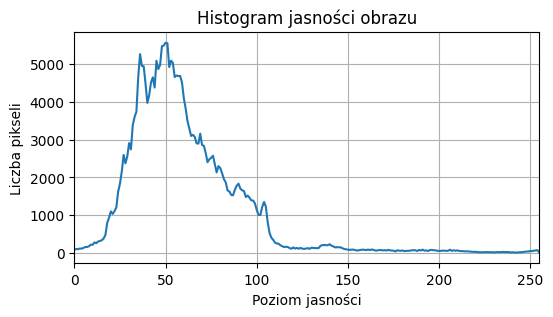

In [22]:
# Narysuj histogram obrazu w skali szarości
gray_8bit = (gray * 255).astype(np.uint8)
hist, bins = np.histogram(
    gray_8bit.flatten(),
    bins=256,
    range=(0, 256)
)


plt.figure(figsize=(6, 3))
plt.plot(hist)

plt.title("Histogram jasności obrazu")
plt.xlabel("Poziom jasności")
plt.ylabel("Liczba pikseli")

plt.xlim([0, 255])
plt.grid()

plt.show()


## 7. Wykonaj normalizację

Wykonaj normalizację obrazu za pomocą:

```python
exposure.rescale_intensity()
```

Przeskaluj wartości pikseli do zakresu:

```text
0–1
```

Wyświetl:

**obraz przed normalizacją | obraz po normalizacji**

Narysuj również histogramy obu obrazów.

### Zastanów się

Czy zakres wartości został rozciągnięty?  
Czy kontrast obrazu zmienił się zauważalnie?  
Jeżeli zmiana jest niewielka, spróbuj wyjaśnić, z czego może to wynikać.


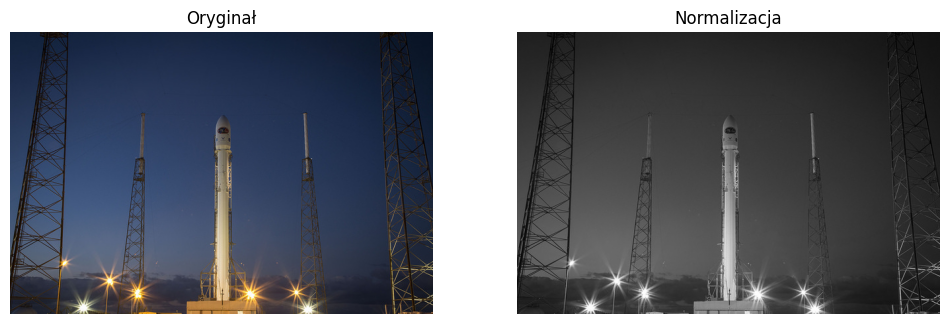

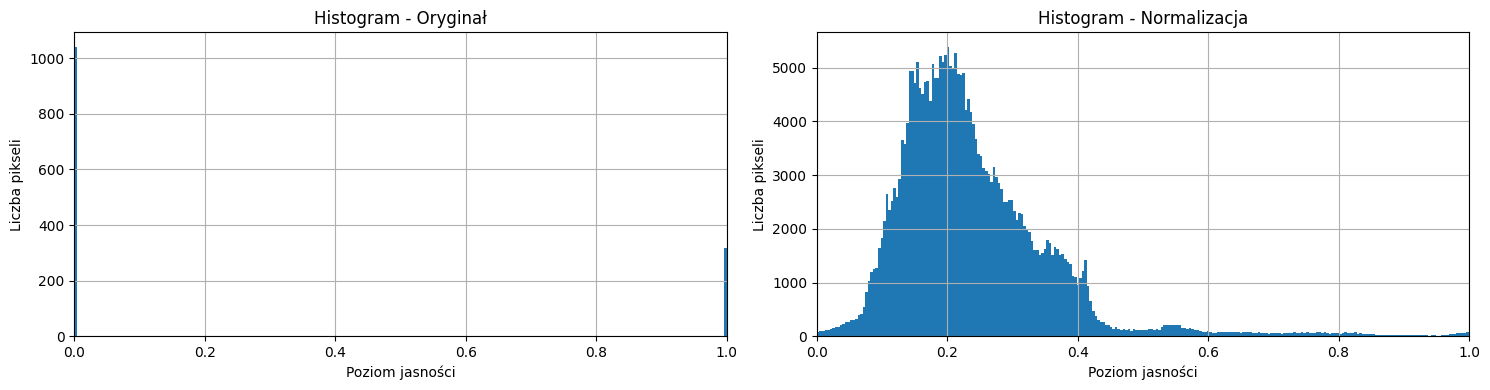

In [23]:
# Wykonaj normalizację i porównaj obraz przed i po normalizacji
norm = exposure.rescale_intensity(gray, in_range='image', out_range=(0, 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
titles = ['Oryginał', 'Normalizacja']

# Wyświetlenie każdego obrazu w skali szarości z odpowiednim tytułem
for ax, im, t in zip(axes, [img, norm], titles):
    ax.imshow(im, cmap='gray')  # Wyświetlenie obrazu w odcieniach szarości
    ax.set_title(t)             # Ustawienie tytułu wykresu
    ax.axis('off')              # Ukrycie osi dla czystszego wyglądu

# Wyświetlenie całej figury
plt.show()


# ============================================================
# Histogramy obrazów
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Histogram obrazu oryginalnego
# ravel() zamienia obraz dwuwymiarowy na jedną tablicę wartości pikseli.
axes[0].hist(img.ravel(), bins=256, range=(0, 1))
axes[0].set_title('Histogram - Oryginał')
axes[0].set_xlabel('Poziom jasności')
axes[0].set_ylabel('Liczba pikseli')
axes[0].set_xlim(0, 1)
axes[0].grid()

# Histogram obrazu po normalizacji
axes[1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1].set_title('Histogram - Normalizacja')
axes[1].set_xlabel('Poziom jasności')
axes[1].set_ylabel('Liczba pikseli')
axes[1].set_xlim(0, 1)
axes[1].grid()

# Dopasowanie odstępów między wykresami
plt.tight_layout()

# Wyświetlenie histogramów
plt.show()

## 8. Wykonaj wyrównanie histogramu

Wykonaj wyrównanie histogramu:

```python
exposure.equalize_hist()
```

Wyświetl:

**obraz przed wyrównaniem | obraz po wyrównaniu**

Narysuj histogram obrazu wynikowego.

### Zastanów się

Jak zmienił się rozkład poziomów jasności?  
Czy szczegóły obrazu stały się bardziej widoczne?  
Czy histogram jest bardziej rozłożony w całym dostępnym zakresie?


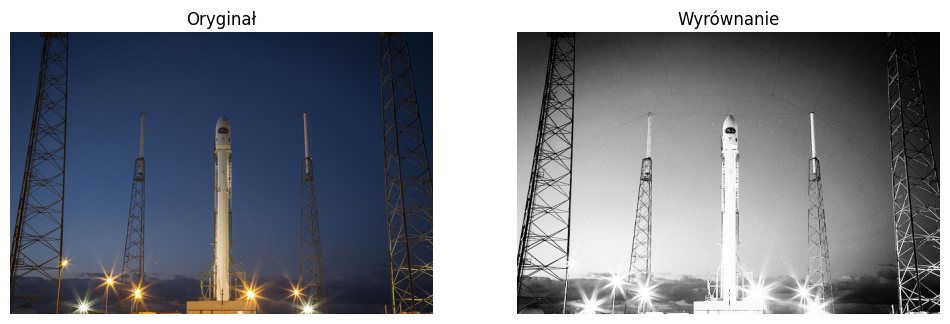

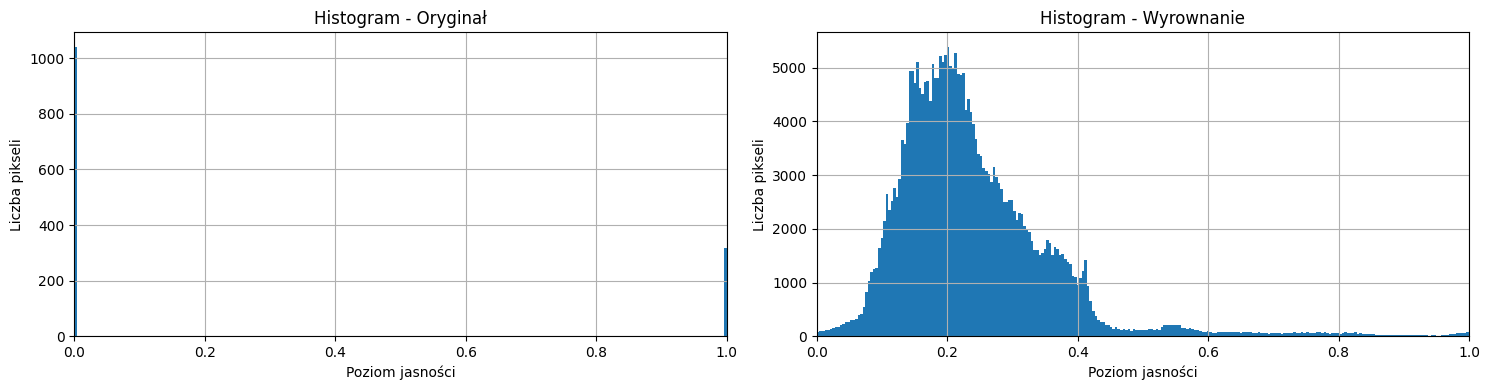

In [ ]:
# Wykonaj wyrównanie histogramu i wyświetl wynik
eq = exposure.equalize_hist(gray)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
titles = ['Oryginał', 'Wyrównanie']

# Wyświetlenie każdego obrazu w skali szarości z odpowiednim tytułem
for ax, im, t in zip(axes, [img, eq], titles):
    ax.imshow(im, cmap='gray')  # Wyświetlenie obrazu w odcieniach szarości
    ax.set_title(t)             # Ustawienie tytułu wykresu
    ax.axis('off')              # Ukrycie osi dla czystszego wyglądu

# Wyświetlenie całej figury
plt.show()


# ============================================================
# Histogramy obrazów
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 4))


axes[0].hist(img.ravel(), bins=256, range=(0, 1))
axes[0].set_title('Histogram - Oryginał')
axes[0].set_xlabel('Poziom jasności')
axes[0].set_ylabel('Liczba pikseli')
axes[0].set_xlim(0, 1)
axes[0].grid()

# Histogram obrazu po normalizacji
axes[1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1].set_title('Histogram - Wyrownanie')
axes[1].set_xlabel('Poziom jasności')
axes[1].set_ylabel('Liczba pikseli')
axes[1].set_xlim(0, 1)
axes[1].grid()


# Dopasowanie odstępów między wykresami
plt.tight_layout()

# Wyświetlenie histogramów
plt.show()


## 9. Porównaj wyniki

Na jednej figurze wyświetl:

```text
Oryginał | Normalizacja | Wyrównanie histogramu
```

Poniżej umieść odpowiadające im histogramy.

Porównaj wygląd obrazów i rozkład intensywności.

### Zastanów się nad różnicą pomiędzy normalizacją i wyrównaniem histogramu

Normalizacja przede wszystkim rozciąga zakres wartości, natomiast wyrównanie histogramu zmienia sposób rozmieszczenia intensywności w tym zakresie.


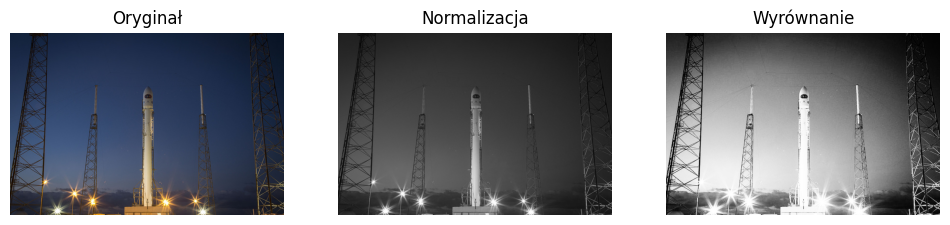

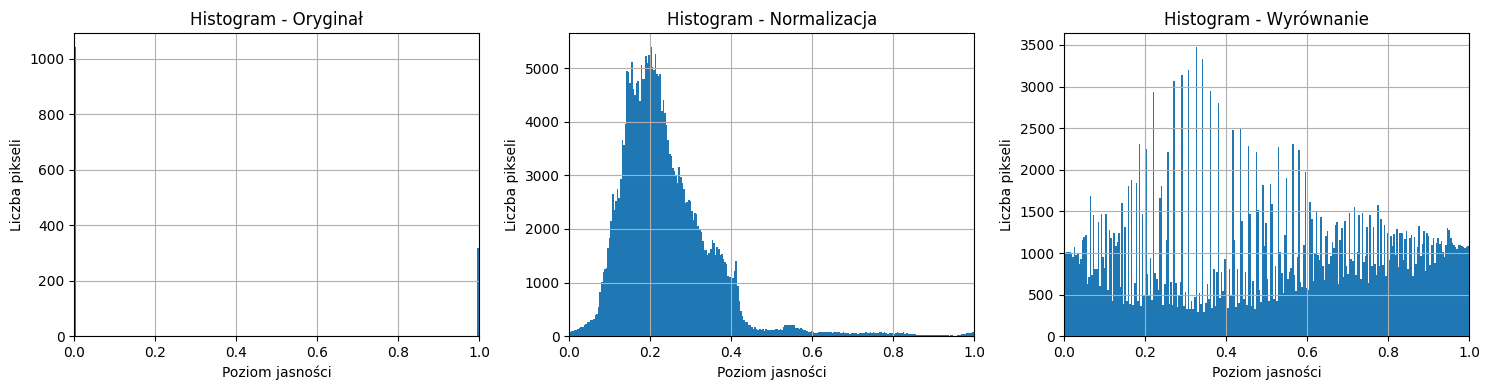

In [25]:
# Porównaj obraz oryginalny, po normalizacji i po wyrównaniu histogramu

# Normalizacja kontrastu
norm = exposure.rescale_intensity(gray, in_range='image', out_range=(0, 1))

# Wyrównanie histogramu (Histogram Equalization)
eq = exposure.equalize_hist(gray)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ['Oryginał', 'Normalizacja', 'Wyrównanie']

# Wyświetlenie każdego obrazu w skali szarości z odpowiednim tytułem
for ax, im, t in zip(axes, [img, norm, eq], titles):
    ax.imshow(im, cmap='gray')  # Wyświetlenie obrazu w odcieniach szarości
    ax.set_title(t)             # Ustawienie tytułu wykresu
    ax.axis('off')              # Ukrycie osi dla czystszego wyglądu

# Wyświetlenie całej figury
plt.show()


# ============================================================
# Histogramy obrazów
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histogram obrazu oryginalnego
axes[0].hist(img.ravel(), bins=256, range=(0, 1))
axes[0].set_title('Histogram - Oryginał')
axes[0].set_xlabel('Poziom jasności')
axes[0].set_ylabel('Liczba pikseli')
axes[0].set_xlim(0, 1)
axes[0].grid()

# Histogram obrazu po normalizacji
axes[1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1].set_title('Histogram - Normalizacja')
axes[1].set_xlabel('Poziom jasności')
axes[1].set_ylabel('Liczba pikseli')
axes[1].set_xlim(0, 1)
axes[1].grid()

# Histogram obrazu po wyrównaniu histogramu
axes[2].hist(eq.ravel(), bins=256, range=(0, 1))
axes[2].set_title('Histogram - Wyrównanie')
axes[2].set_xlabel('Poziom jasności')
axes[2].set_ylabel('Liczba pikseli')
axes[2].set_xlim(0, 1)
axes[2].grid()

# Dopasowanie odstępów między wykresami
plt.tight_layout()

# Wyświetlenie histogramów
plt.show()